<a href="https://colab.research.google.com/github/NiloferMubeen/OceanLens-Endangered-Marine-Species-Classification-Detection/blob/main/oceanlens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importing the required Libraries

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix

# Using the GPU

In [14]:
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

# Mounting drive

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
train_dir = '/content/drive/MyDrive/Projects/Myprojects/oceanlens/train'
val_dir = '/content/drive/MyDrive/Projects/Myprojects/oceanlens/val'
test_dir = "/content/drive/MyDrive/Projects/Myprojects/oceanlens/test"

# Data Augumentation

In [16]:
# Training data generator with augmentation
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize pixel values to [0, 1]

    # Data augmentation parameters
    rotation_range=20,  # Random rotation between -20 and +20 degrees
    width_shift_range=0.2,  # Random horizontal shift by ±20% of width
    height_shift_range=0.2,  # Random vertical shift by ±20% of height
    zoom_range=0.2,  # Random zoom between 80% and 120%
    horizontal_flip=True,  # Random horizontal flipping
    vertical_flip=False,  # No vertical flipping (can enable if appropriate)
    fill_mode='nearest'  # Strategy for filling in newly created pixels
)

# Validation and test generators (only rescaling, no augmentation)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [17]:
# Set image size and batch size
img_width, img_height = 224, 224  # Adjust as needed
batch_size = 32  # Adjust as needed

# Create data generators
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical'  # or 'binary' if you have two classes
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False  # Important for evaluating the test set
)

Found 2640 images belonging to 6 classes.
Found 623 images belonging to 6 classes.
Found 353 images belonging to 6 classes.


# Get the classnames and number of classes

In [18]:
test_generator.class_indices

{'bottlenose_dolphin': 0,
 'green_turtle': 1,
 'hammerhead_shark': 2,
 'hawaiian_monk_seal': 3,
 'north_atlantic_right_whale': 4,
 'whale_shark': 5}

In [19]:
class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)
print(f"Class names: {class_names}")
print(f"Number of classes: {num_classes}")

Class names: ['bottlenose_dolphin', 'green_turtle', 'hammerhead_shark', 'hawaiian_monk_seal', 'north_atlantic_right_whale', 'whale_shark']
Number of classes: 6


# Building a custom model

In [9]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_height, img_width, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy',
                       tf.keras.metrics.Precision(name='precision'),
                       tf.keras.metrics.Recall(name='recall')])

# Model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
epochs = 10
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    epochs=epochs,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // batch_size
)

Epoch 1/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 362s 4s/step - accuracy: 0.5452 - loss: 1.1457 - precision: 0.6624 - recall: 0.3581 - val_accuracy: 0.5740 - val_loss: 1.1465 - val_precision: 0.6927 - val_recall: 0.4523
Epoch 2/10
 1/82 ━━━━━━━━━━━━━━━━━━━━ 5:31 4s/step - accuracy: 0.5625 - loss: 0.9447 - precision: 0.6923 - recall: 0.5625

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


82/82 ━━━━━━━━━━━━━━━━━━━━ 25s 256ms/step - accuracy: 0.5625 - loss: 0.9447 - precision: 0.6923 - recall: 0.5625 - val_accuracy: 0.6497 - val_loss: 1.0974 - val_precision: 0.7250 - val_recall: 0.4770
Epoch 3/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 444s 5s/step - accuracy: 0.7212 - loss: 0.7283 - precision: 0.7687 - recall: 0.6549 - val_accuracy: 0.5395 - val_loss: 1.1166 - val_precision: 0.5763 - val_recall: 0.4408
Epoch 4/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 40s 463ms/step - accuracy: 0.8125 - loss: 0.6281 - precision: 0.8125 - recall: 0.8125 - val_accuracy: 0.6135 - val_loss: 1.0093 - val_precision: 0.6568 - val_recall: 0.5132
Epoch 5/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 349s 4s/step - accuracy: 0.7665 - loss: 0.6249 - precision: 0.8060 - recall: 0.7170 - val_accuracy: 0.7072 - val_loss: 0.9212 - val_precision: 0.7477 - val_recall: 0.6727
Epoch 6/10
82/82 ━━━━━━━━━━━━━━━━━━━━ 41s 470ms/step - accuracy: 0.8125 - loss: 0.3933 - precision: 0.8667 - recall: 0.8125 - val_accuracy: 0.7023 - val_loss: 0.9313 - val

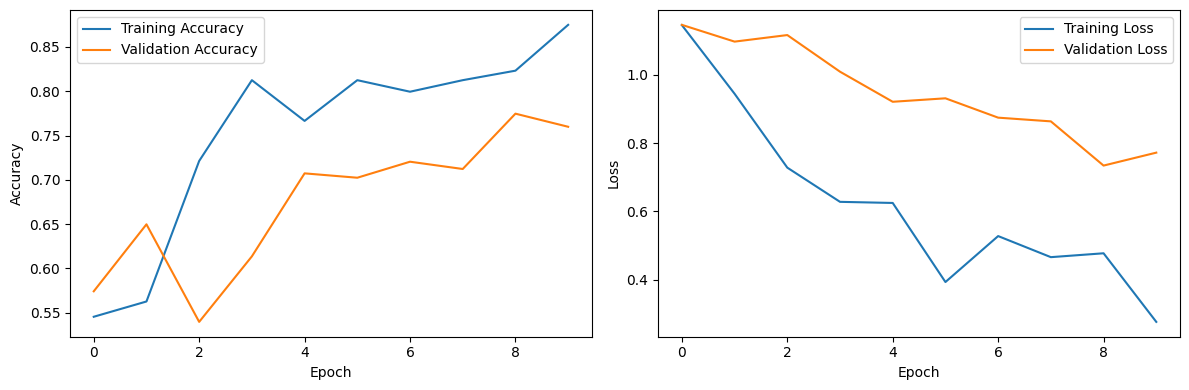

In [12]:
def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)

In [13]:
test_loss, test_acc, test_precision, test_recall = model.evaluate(test_generator)
print(f'\nTest accuracy: {test_acc:.4f}')
print(f'Test precision: {test_precision:.4f}')
print(f'Test recall: {test_recall:.4f}')

12/12 ━━━━━━━━━━━━━━━━━━━━ 128s 11s/step - accuracy: 0.8045 - loss: 0.6097 - precision: 0.8252 - recall: 0.7620

Test accuracy: 0.8045
Test precision: 0.8252
Test recall: 0.7620


In [14]:
test_generator.reset()
predictions = model.predict(test_generator, steps=test_generator.samples // batch_size + 1)
predicted_classes = np.argmax(predictions, axis=1)

12/12 ━━━━━━━━━━━━━━━━━━━━ 11s 927ms/step


In [15]:
true_classes = test_generator.classes

In [16]:
print('\nClassification Report:')
print(classification_report(true_classes, predicted_classes, target_names=class_names))

# Confusion matrix
conf_mat = confusion_matrix(true_classes, predicted_classes)
print('\nConfusion Matrix:')
print(conf_mat)


Classification Report:
                            precision    recall  f1-score   support

        bottlenose_dolphin       0.95      0.91      0.93        78
              green_turtle       0.62      0.65      0.63        20
          hammerhead_shark       0.81      0.71      0.75        85
        hawaiian_monk_seal       0.82      0.77      0.79        47
north_atlantic_right_whale       0.67      0.96      0.79        50
               whale_shark       0.84      0.77      0.80        73

                  accuracy                           0.80       353
                 macro avg       0.78      0.79      0.78       353
              weighted avg       0.82      0.80      0.80       353


Confusion Matrix:
[[71  0  6  1  0  0]
 [ 1 13  0  3  2  1]
 [ 0  5 60  4  7  9]
 [ 0  0  0 36 11  0]
 [ 1  0  0  0 48  1]
 [ 2  3  8  0  4 56]]


# Using Transfer Learning models

In [20]:
from tensorflow.keras.applications import (VGG16, ResNet50, MobileNet,
                                          InceptionV3, EfficientNetB0)
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

model_comparison = []

# 1. VGG16

In [21]:
def evaluate_vgg16():
    base_model = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy',
                         tf.keras.metrics.Precision(name='precision'),
                         tf.keras.metrics.Recall(name='recall')])

    history = model.fit(
        train_generator,
        validation_data=validation_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

vgg_model, vgg_history = evaluate_vgg16()
model_comparison.append({
    'Model': 'VGG16',
    'Val Accuracy': max(vgg_history.history['val_accuracy']),
    'Val Precision': max(vgg_history.history['val_precision']),
    'Val Recall': max(vgg_history.history['val_recall']),
    'Parameters': f"{vgg_model.count_params():,}",
    'Inference Time': 'Medium',
    'Best For': 'Medium-sized datasets'
})

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1398s 17s/step - accuracy: 0.3303 - loss: 1.6395 - precision: 0.2500 - recall: 0.0023 - val_accuracy: 0.6356 - val_loss: 1.4201 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 59s 710ms/step - accuracy: 0.6314 - loss: 1.2740 - precision: 0.9670 - recall: 0.0333 - val_accuracy: 0.7560 - val_loss: 1.1698 - val_precision: 0.9024 - val_recall: 0.0594
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 60s 723ms/step - accuracy: 0.7614 - loss: 1.0392 - precision: 0.9509 - recall: 0.1614 - val_accuracy: 0.7464 - val_loss: 1.0260 - val_precision: 0.9128 - val_recall: 0.2857
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 58s 702ms/step - accuracy: 0.7909 - loss: 0.8983 - precision: 0.9555 - recall: 0.3659 - val_accuracy: 0.7769 - val_loss: 0.9262 - val_precision: 0.9134 - val_recall: 0.4061
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 60s 721ms/step - accuracy: 0.8178 - loss: 0.7985 - precisio

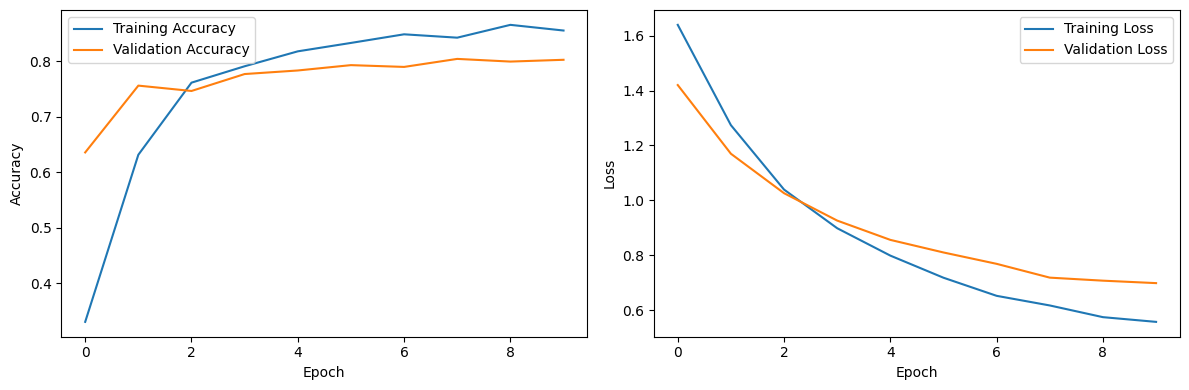

12/12 ━━━━━━━━━━━━━━━━━━━━ 152s 14s/step - accuracy: 0.8527 - loss: 0.5518 - precision: 0.9081 - recall: 0.7280

Test accuracy: 0.8527
Test precision: 0.9081
Test recall: 0.7280
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 255ms/step


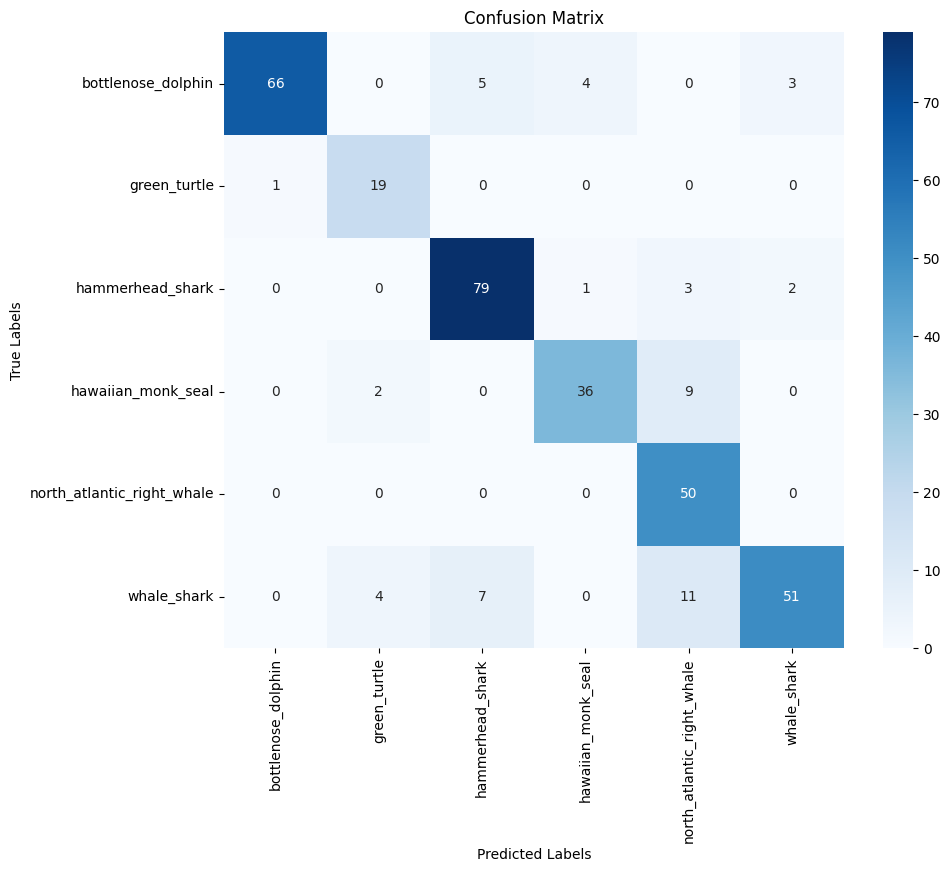

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(vgg_history)


# Evaluate on test set (assuming you have a test_generator)
test_generator.reset() # Reset the generator before evaluating
test_loss, test_acc, test_precision, test_recall = vgg_model.evaluate(test_generator)
print(f'\nTest accuracy: {test_acc:.4f}')
print(f'Test precision: {test_precision:.4f}')
print(f'Test recall: {test_recall:.4f}')


# Generate predictions
predictions = vgg_model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# Get true classes
true_classes = test_generator.classes

# Confusion Matrix
conf_mat = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

# 2. RESNET50

In [23]:
def evaluate_resnet50():
    base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = tf.keras.applications.resnet50.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        train_generator,
        validation_data=validation_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

resnet_model, resnet_history = evaluate_resnet50()
model_comparison.append({
    'Model': 'ResNet50',
    'Val Accuracy': max(resnet_history.history['val_accuracy']),
    'Val Precision': max(resnet_history.history['val_precision']),
    'Val Recall': max(resnet_history.history['val_recall']),
    'Parameters': f"{resnet_model.count_params():,}",
    'Inference Time': 'Medium',
    'Best For': 'General purpose'
})

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.2133 - loss: 1.8039 - precision: 0.1600 - recall: 0.0015 - val_accuracy: 0.2889 - val_loss: 1.7837 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 59s 707ms/step - accuracy: 0.2432 - loss: 1.7461 - precision: 0.7500 - recall: 0.0011 - val_accuracy: 0.1621 - val_loss: 1.7515 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 58s 697ms/step - accuracy: 0.2636 - loss: 1.7146 - precision: 0.7778 - recall: 0.0027 - val_accuracy: 0.3515 - val_loss: 1.7147 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 59s 708ms/step - accuracy: 0.2841 - loss: 1.6845 - precision: 0.8667 - recall: 0.0049 - val_accuracy: 0.2231 - val_loss: 1.7229 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 58s 695ms/step - accuracy: 0.2902 - l

# 3. MobileNet

In [24]:
def evaluate_mobilenet():
    base_model = MobileNet(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        train_generator,
        validation_data=validation_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

mobilenet_model, mobilenet_history = evaluate_mobilenet()
model_comparison.append({
    'Model': 'MobileNet',
    'Val Accuracy': max(mobilenet_history.history['val_accuracy']),
    'Val Precision': max(mobilenet_history.history['val_precision']),
    'Val Recall': max(mobilenet_history.history['val_recall']),
    'Parameters': f"{mobilenet_model.count_params():,}"
})

17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 91s 912ms/step - accuracy: 0.7098 - loss: 0.8382 - precision: 0.8322 - recall: 0.6144 - val_accuracy: 0.8732 - val_loss: 0.4590 - val_precision: 0.8830 - val_recall: 0.8604
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 55s 665ms/step - accuracy: 0.9284 - loss: 0.2292 - precision: 0.9471 - recall: 0.9083 - val_accuracy: 0.8989 - val_loss: 0.3058 - val_precision: 0.9064 - val_recall: 0.8860
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 54s 652ms/step - accuracy: 0.9489 - loss: 0.1549 - precision: 0.9613 - recall: 0.9420 - val_accuracy: 0.8973 - val_loss: 0.2995 - val_precision: 0.9145 - val_recall: 0.8925
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 54s 657ms/step - accuracy: 0.9610 - loss: 0.1246 - precision: 0.9677 - recall: 0.9542 - val_accuracy: 0.9069 - val_loss: 0.2703 - val_precision: 0.9230 - val_recall: 0.9037
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 53s 643ms/step - accuracy: 0.9689 - loss: 0.1047 - precision: 0.975

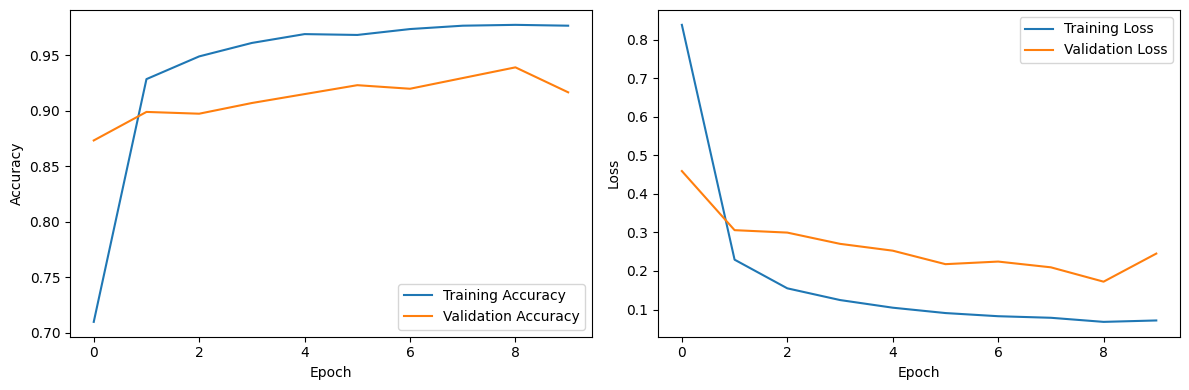

In [25]:
plot_history(mobilenet_history)

12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 853ms/step - accuracy: 0.9745 - loss: 0.0948 - precision: 0.9745 - recall: 0.9745

MobileNet Test accuracy: 0.9745
MobileNet Test precision: 0.9745
MobileNet Test recall: 0.9745
12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 335ms/step


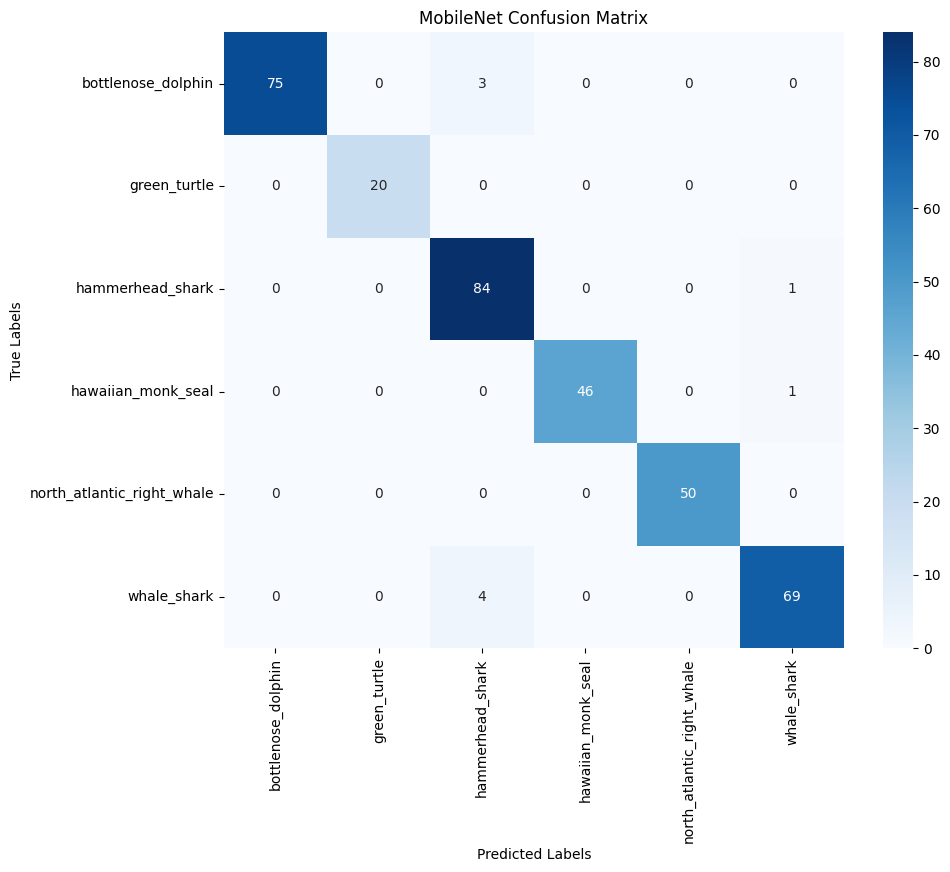

In [26]:
test_generator.reset()  # Reset the generator before evaluating
test_loss, test_acc, test_precision, test_recall = mobilenet_model.evaluate(test_generator)
print(f'\nMobileNet Test accuracy: {test_acc:.4f}')
print(f'MobileNet Test precision: {test_precision:.4f}')
print(f'MobileNet Test recall: {test_recall:.4f}')

# Generate predictions for MobileNet
predictions = mobilenet_model.predict(test_generator)
predicted_classes = np.argmax(predictions, axis=1)

# Get true classes for MobileNet
true_classes = test_generator.classes

# Confusion Matrix for MobileNet
conf_mat = confusion_matrix(true_classes, predicted_classes)

# Plot confusion matrix for MobileNet using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('MobileNet Confusion Matrix')
plt.show()

# 4. InceptionV3

In [27]:
def evaluate_inception():
    # Special generator for Inception's 299x299 input
    inception_train_gen = train_datagen.flow_from_directory(
        train_dir, target_size=(299, 299), batch_size=batch_size)
    inception_val_gen = val_datagen.flow_from_directory(
        val_dir, target_size=(299, 299), batch_size=batch_size)

    base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
    base_model.trainable = False

    inputs = tf.keras.Input(shape=(299, 299, 3))
    x = tf.keras.applications.inception_v3.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        inception_train_gen,
        validation_data=inception_val_gen,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

inception_model, inception_history = evaluate_inception()
model_comparison.append({
    'Model': 'InceptionV3',
    'Val Accuracy': max(inception_history.history['val_accuracy']),
    'Val Precision': max(inception_history.history['val_precision']),
    'Val Recall': max(inception_history.history['val_recall']),
    'Parameters': f"{inception_model.count_params():,}",
    'Inference Time': 'Medium',
    'Best For': 'Multi-scale features'
})

Found 2640 images belonging to 6 classes.
Found 623 images belonging to 6 classes.
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 195s 2s/step - accuracy: 0.2428 - loss: 1.7218 - precision: 0.7500 - recall: 0.0023 - val_accuracy: 0.2632 - val_loss: 1.6710 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 82s 990ms/step - accuracy: 0.3436 - loss: 1.5985 - precision: 0.7714 - recall: 0.0102 - val_accuracy: 0.3724 - val_loss: 1.6037 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 87s 1s/step - accuracy: 0.4049 - loss: 1.5164 - precision: 0.7500 - recall: 0.0227 - val_accuracy: 0.3435 - val_loss: 1.5714 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 85s 1s/step - accuracy: 0.4398 - loss: 1.4612 - precision: 0.8462 - recall: 0.0333 - val_accuracy: 0.4125 - val_loss: 1.5320 - val_precision: 0.0000e+00 - val_recall: 0.0000e+0

# 5. EfficientNet

In [28]:
def evaluate_efficientnet():
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = tf.keras.Sequential([
        base_model,
        GlobalAveragePooling2D(),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer=Adam(0.001),
                 loss='categorical_crossentropy',
                 metrics=['accuracy', 'precision', 'recall'])

    history = model.fit(
        train_generator,
        validation_data= validation_generator,
        epochs=10,
        callbacks=[EarlyStopping(patience=3)]
    )

    return model, history

efficientnet_model, efficientnet_history = evaluate_efficientnet()
model_comparison.append({
    'Model': 'EfficientNetB0',
    'Val Accuracy': max(efficientnet_history.history['val_accuracy']),
    'Val Precision': max(efficientnet_history.history['val_precision']),
    'Val Recall': max(efficientnet_history.history['val_recall']),
    'Parameters': f"{efficientnet_model.count_params():,}",
    'Inference Time': 'Fast',
    'Best For': 'Best accuracy/efficiency tradeoff'
})

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - accuracy: 0.1977 - loss: 1.7795 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.2087 - val_loss: 1.7548 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 106s 652ms/step - accuracy: 0.2049 - loss: 1.7657 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.2087 - val_loss: 1.7608 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 57s 678ms/step - accuracy: 0.2023 - loss: 1.7685 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.2087 - val_loss: 1.7573 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 56s 679ms/step - accuracy: 0.1970 - loss: 1.7748 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.1413 - val_loss: 1.7834 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00


# Models comparison

In [29]:
import pandas as pd
comparison_df = pd.DataFrame(model_comparison)
comparison_df = comparison_df.sort_values('Val Accuracy', ascending=False)
comparison_df.style.background_gradient(cmap='Blues', subset=['Val Accuracy', 'Val Precision', 'Val Recall'])

,Model,Val Accuracy,Val Precision,Val Recall,Parameters,Inference Time,Best For
2,MobileNet,0.939005,0.946429,0.935795,"3,235,014",Fast,Mobile/Edge devices
0,VGG16,0.804173,0.913357,0.669342,"14,717,766",Medium,Medium-sized datasets
3,InceptionV3,0.528090,0.813333,0.097913,"21,815,078",Medium,Multi-scale features
1,ResNet50,0.436597,0.428571,0.009631,"23,600,006",Medium,General purpose
4,EfficientNetB0,0.208668,0.000000,0.000000,"4,057,257",Fast,Best accuracy/efficiency tradeoff


# Save the model

In [30]:
mobilenet_model.save('/content/drive/MyDrive/model.h5')

# Streamlit App

In [ ]:
!pip install streamlit numpy pillow tensorflow

In [ ]:
%%writefile app.py

import streamlit as st
import numpy as np
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import img_to_array
from tensorflow.keras.models import load_model
import os


classes = ['glioma', 'meningioma', 'no_tumor', 'pituitary']

# Load the trained model
@st.cache_resource
def load_custom_model():
    model_path = '/content/drive/MyDrive/model.h5'
    if not os.path.exists(model_path):
        st.error(f"Model file not found at {model_path}")
        return None
    return load_model(model_path)

model = load_custom_model()

# Streamlit app
st.title("🎣 Custom Brain Tumour Classifier")
st.write(f"Upload a Tumour to classify")

# File uploader
uploaded_file = st.file_uploader("Choose an image...",
                                type=["jpg", "jpeg", "png"])

if uploaded_file is not None and model is not None:
    # Display the uploaded image
    image = Image.open(uploaded_file)
    st.image(image, caption='Uploaded Image', use_column_width=True)

    # Preprocess the image
    image = image.resize((224, 224))  # Match your model's expected input
    image_array = img_to_array(image)
    image_array = image_array / 255.0  # Normalize (if your model expects this)
    image_array = np.expand_dims(image_array, axis=0)

    # Make prediction
    with st.spinner('Identifying Tumour...'):
        predictions = model.predict(image_array)
        predicted_class = classes[np.argmax(predictions)]
        confidence = np.max(predictions)


    # Display results
    st.subheader("Predicted Results:")
    st.success(f"Tumour: {predicted_class}")
    st.info(f"Confidence: {confidence*100:.2f}%")

    # Show all class probabilities
    st.subheader("All Class Probabilities:")
    for i, (cls, prob) in enumerate(zip(classes, predictions[0])):
        st.write(f"{cls}: {prob*100:.2f}%")
        st.progress(float(prob))